# Phase 3: Data Cleaning and Preprocessing

## Objective
Convert raw bank marketing data into a clean, ML-ready format while preventing data leakage.

This notebook covers data quality, outlier analysis, categorical and numerical preprocessing, class imbalance, and preparation of a reusable preprocessing pipeline.

## 1. Import Libraries

Import the libraries required for data inspection, visualization and preprocessing.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


## 2. Load Raw Dataset

Load the original semicolon-separated training dataset. The raw source file will remain unchanged.

In [41]:
DATA_PATH = Path('../data/raw/bank.csv')
df = pd.read_csv(DATA_PATH, sep=';')

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


## 3. Initial Data Quality Inspection

Inspect data types, missing values, duplicate records, and target distribution before making cleaning decisions.

In [42]:
display(df.info())
display(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
display(df['y'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB


None

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows: 0


y
no     4000
yes     521
Name: count, dtype: int64

## 4. Detailed Data Quality Investigation

Inspect numerical ranges and categorical values to identify
invalid entries, inconsistent categories, and unusual observations
before applying any cleaning transformations.

In [43]:
# Numerical feature summary
numerical_cols = df.select_dtypes(include="number").columns.tolist()

print("NUMERICAL FEATURE SUMMARY")
display(df[numerical_cols].describe().T)

# Unique categorical values
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("\nUNIQUE CATEGORICAL VALUES")

for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique().tolist()))

# Check unusual or potentially invalid numerical values
print("\nNUMERICAL VALIDATION")

validation_checks = {
    "age <= 0": df["age"] <= 0,
    "day outside 1-31": ~df["day"].between(1, 31),
    "negative balance": df["balance"] < 0,
    "negative duration": df["duration"] < 0,
    "campaign < 1": df["campaign"] < 1,
    "invalid pdays (< -1)": df["pdays"] < -1,
    "negative previous": df["previous"] < 0
}

for label, condition in validation_checks.items():
    print(f"{label}: {condition.sum()} records")

NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
age,4521.0,41.170095,10.576211,19.0,33.0,39.0,49.0,87.0
balance,4521.0,1422.657819,3009.638142,-3313.0,69.0,444.0,1480.0,71188.0
day,4521.0,15.915284,8.247667,1.0,9.0,16.0,21.0,31.0
duration,4521.0,263.961292,259.856633,4.0,104.0,185.0,329.0,3025.0
campaign,4521.0,2.793630,3.109807,1.0,1.0,2.0,3.0,50.0
pdays,4521.0,39.766645,100.121124,-1.0,-1.0,-1.0,-1.0,871.0
previous,4521.0,0.542579,1.693562,0.0,0.0,0.0,0.0,25.0



UNIQUE CATEGORICAL VALUES

job:
['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']

marital:
['divorced', 'married', 'single']

education:
['primary', 'secondary', 'tertiary', 'unknown']

default:
['no', 'yes']

housing:
['no', 'yes']

loan:
['no', 'yes']

contact:
['cellular', 'telephone', 'unknown']

month:
['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']

poutcome:
['failure', 'other', 'success', 'unknown']

y:
['no', 'yes']

NUMERICAL VALIDATION
age <= 0: 0 records
day outside 1-31: 0 records
negative balance: 366 records
negative duration: 0 records
campaign < 1: 0 records
invalid pdays (< -1): 0 records
negative previous: 0 records


In [44]:
# 1. Compact numerical validation summary

validation_summary = pd.DataFrame({
    "Invalid Condition": [
        "Age <= 0",
        "Day outside 1-31",
        "Negative balance",
        "Negative duration",
        "Campaign < 1",
        "Pdays < -1",
        "Negative previous"
    ],
    "Record Count": [
        (df["age"] <= 0).sum(),
        (~df["day"].between(1, 31)).sum(),
        (df["balance"] < 0).sum(),
        (df["duration"] < 0).sum(),
        (df["campaign"] < 1).sum(),
        (df["pdays"] < -1).sum(),
        (df["previous"] < 0).sum()
    ]
})

display(validation_summary)


# 2. Count unknown values in categorical features

unknown_summary = pd.DataFrame({
    "Unknown Count": [
        (df[col] == "unknown").sum()
        for col in categorical_cols
    ],
    "Unknown Percentage": [
        (df[col] == "unknown").mean() * 100
        for col in categorical_cols
    ]
}, index=categorical_cols)

display(unknown_summary.sort_values(
    "Unknown Count",
    ascending=False
))


# 3. Check whitespace inconsistencies

print("Leading/trailing whitespace checks:")

for col in categorical_cols:
    count = (
        df[col].notna()
        & (df[col] != df[col].str.strip())
    ).sum()

    print(f"{col}: {count}")

,Invalid Condition,Record Count
0,Age <= 0,0
1,Day outside 1-31,0
2,Negative balance,366
3,Negative duration,0
4,Campaign < 1,0
5,Pdays < -1,0
6,Negative previous,0


,Unknown Count,Unknown Percentage
poutcome,3705,81.950896
contact,1324,29.285556
education,187,4.136253
job,38,0.840522
marital,0,0.000000
default,0,0.000000
housing,0,0.000000
loan,0,0.000000
month,0,0.000000
y,0,0.000000


Leading/trailing whitespace checks:
job: 0
marital: 0
education: 0
default: 0
housing: 0
loan: 0
contact: 0
month: 0
poutcome: 0
y: 0


## 5. Outlier Analysis Using IQR and Boxplots

Use boxplots and the Interquartile Range (IQR) method to
identify potentially extreme numerical observations.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

IQR identifies statistical outliers, but these observations
will not automatically be removed because they may represent
valid customers.

In [45]:
# Select numerical features
numerical_cols = df.select_dtypes(include="number").columns.tolist()

# Calculate IQR-based outlier statistics
outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_count / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.round(2).sort_values(
        "Outlier Count",
        ascending=False
    )
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,pdays,-1.0,-1.0,0.0,-1.0,-1.0,816,18.05
6,previous,0.0,0.0,0.0,0.0,0.0,816,18.05
1,balance,69.0,1480.0,1411.0,-2047.5,3596.5,506,11.19
3,duration,104.0,329.0,225.0,-233.5,666.5,330,7.30
4,campaign,1.0,3.0,2.0,-2.0,6.0,318,7.03
0,age,33.0,49.0,16.0,9.0,73.0,38,0.84
2,day,9.0,21.0,12.0,-9.0,39.0,0,0.00


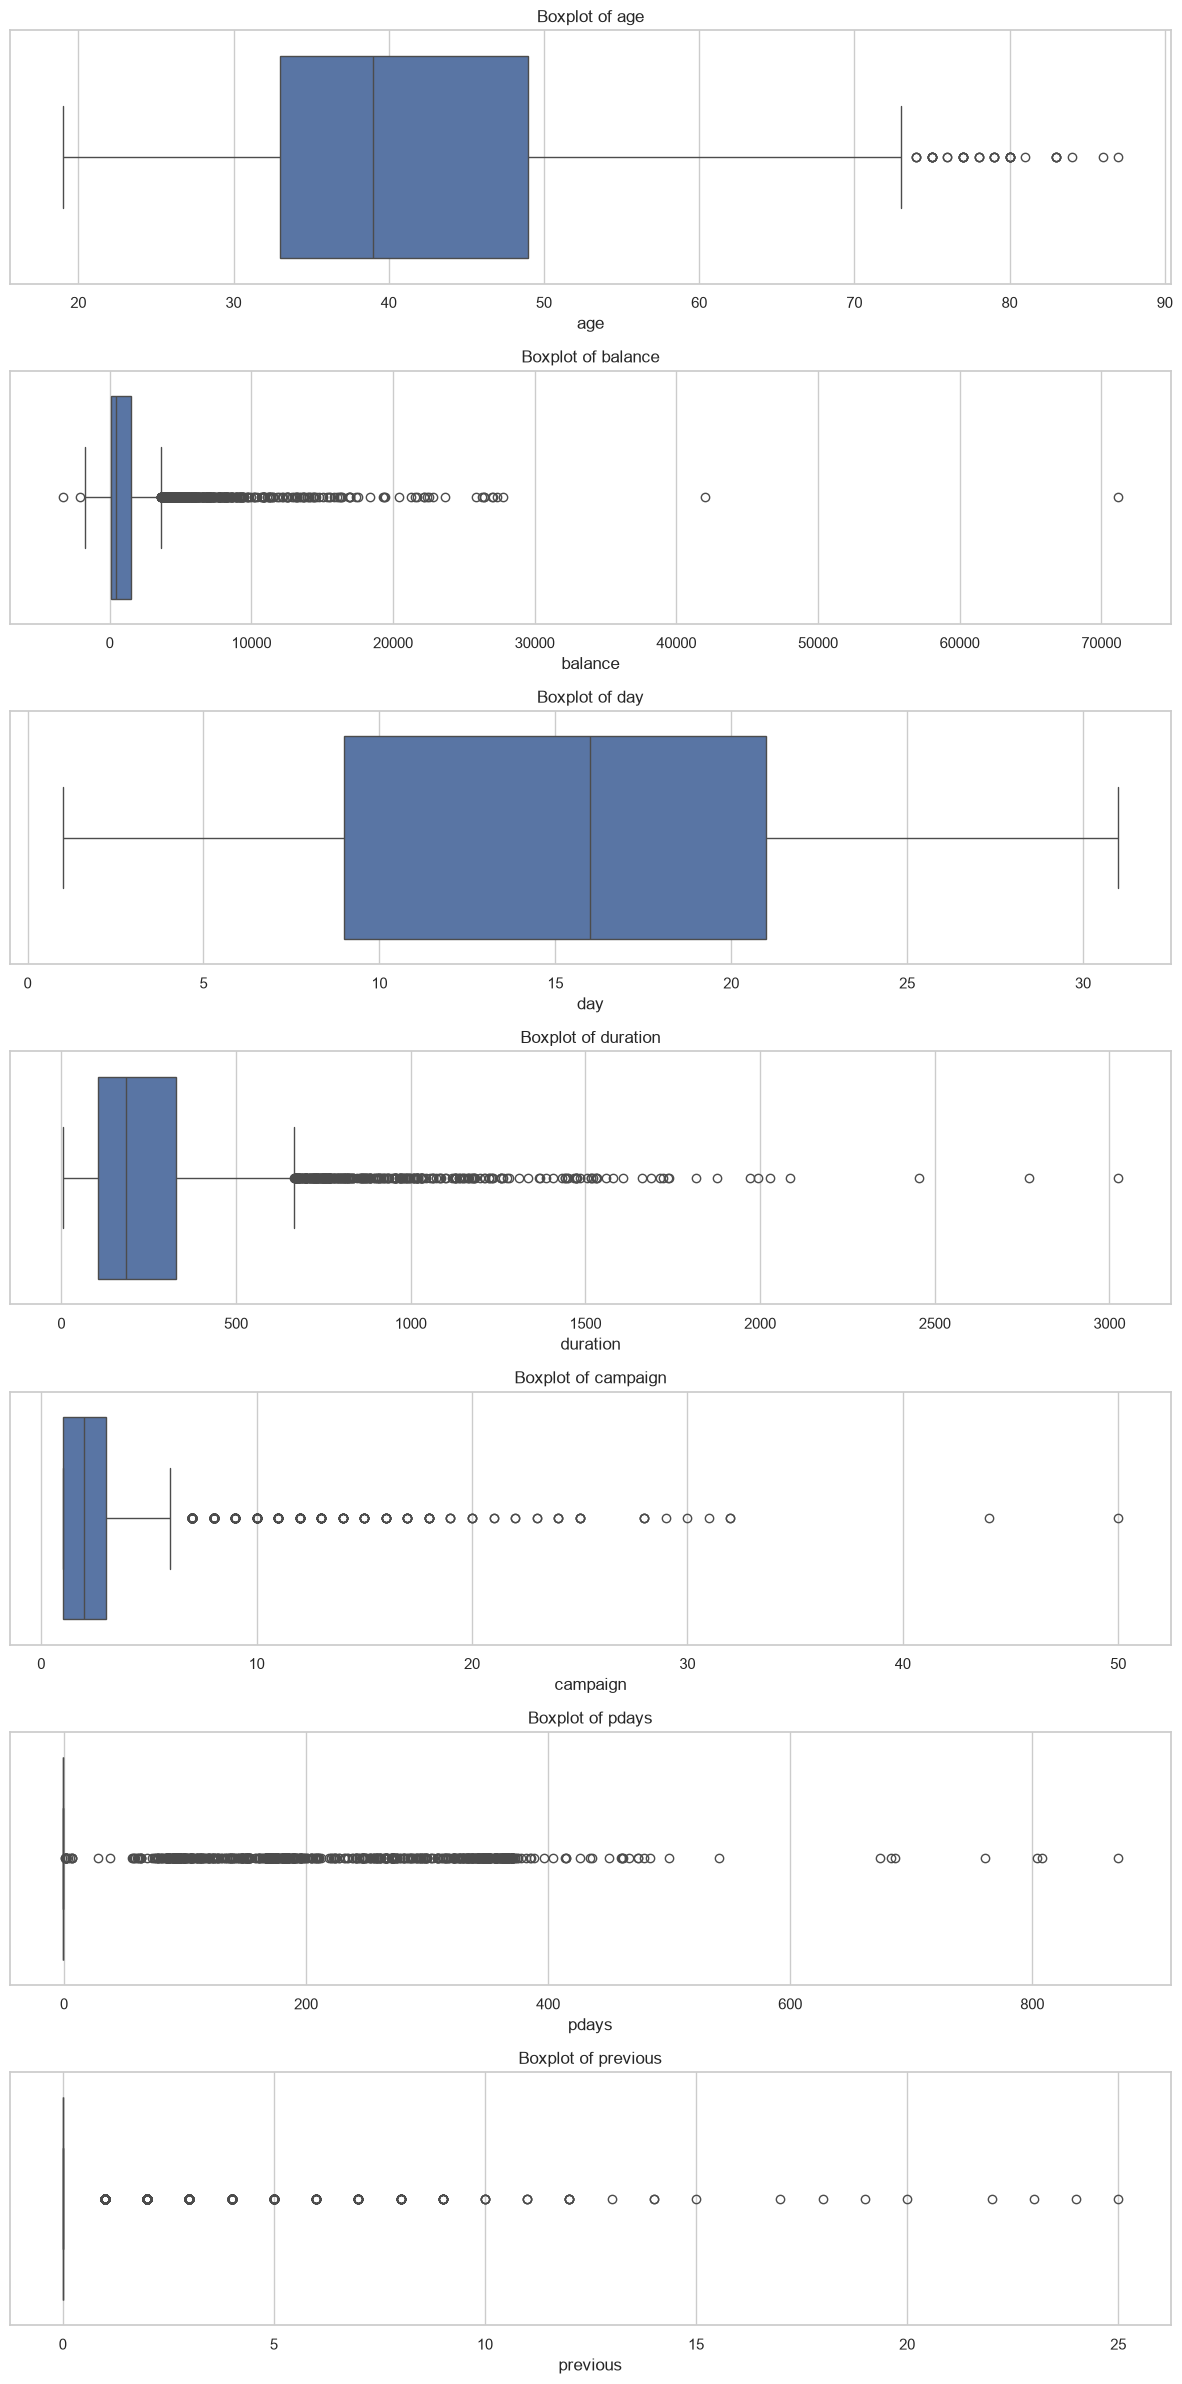

In [46]:
# Boxplots for numerical features

fig, axes = plt.subplots(
    len(numerical_cols),
    1,
    figsize=(12, 24)
)

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

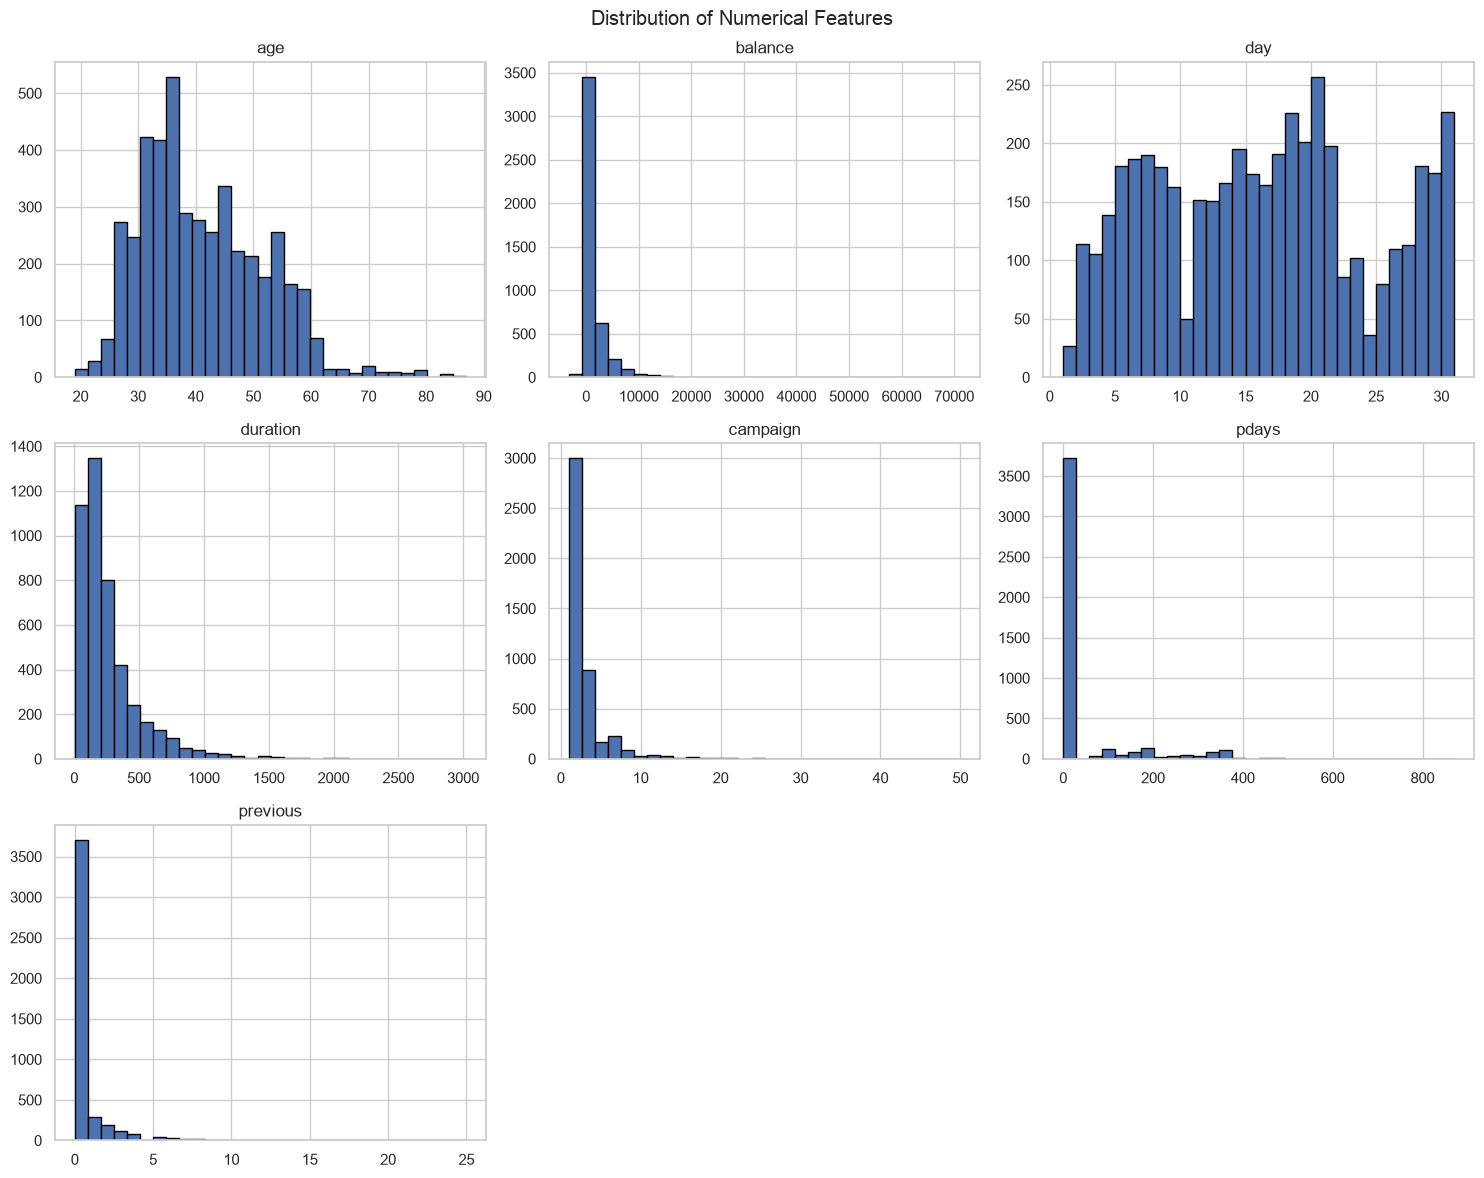

In [47]:
# Distribution analysis

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


### Outlier Analysis — Observations and Decisions

1. The balance feature contains 506 IQR-flagged observations.
   Negative and unusually high balances may represent genuine
   customer financial conditions.

2. The duration feature contains 330 IQR-flagged observations.
   It is right-skewed and will be excluded from the primary
   predictive model because it is known only after a call ends.

3. The campaign feature contains 318 IQR-flagged observations.
   High contact counts may represent genuine marketing activity.

4. The age feature contains 38 IQR-flagged observations.
   These values are within the observed customer age range.

5. The pdays and previous features have an IQR of zero because
   their distributions contain many repeated sentinel or zero
   values. Their IQR outlier counts are therefore not meaningful
   as conventional outlier counts.

6. The day feature contains no IQR-flagged observations.

**Cleaning decision:** No observations will be removed solely
because they are flagged by the IQR method. Valid extreme values
and documented special values will be preserved.


In [48]:
# Conditional IQR analysis for zero-inflated features

conditional_data = {
    "pdays (previously contacted customers)": df.loc[df["pdays"] >= 0, "pdays"],
    "previous (customers with previous contacts)": df.loc[df["previous"] > 0, "previous"]
}

conditional_results = []

for feature, values in conditional_data.items():

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((values < lower) | (values > upper)).sum()

    conditional_results.append({
        "Feature": feature,
        "Records Analyzed": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers": outliers
    })

conditional_iqr_df = pd.DataFrame(conditional_results)

display(conditional_iqr_df.round(2))

,Feature,Records Analyzed,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,pdays (previously contacted customers),816,136.0,330.0,194.0,-155.0,621.0,7
1,previous (customers with previous contacts),816,1.0,4.0,3.0,-3.5,8.5,34



### Conditional IQR Analysis — Observations

The initial IQR analysis produced zero IQR values for
pdays and previous because most observations were -1
and 0 respectively.

To obtain a more meaningful analysis, these features
were investigated separately:

- pdays: Only customers with pdays >= 0 were analyzed.
  Outliers detected: 7 among 816 records.

- previous: Only customers with previous > 0 were analyzed.
  Outliers detected: 34 among 816 records.

These observations are statistical outliers, not
necessarily invalid records.

**Decision:** All valid observations will be retained.
No automatic IQR-based row removal or capping will
be performed.


## 6. Data Cleaning and Validation

Apply only justified cleaning operations based on the
previous data-quality investigation.

The raw dataset will remain unchanged. Valid extreme
values, negative balances, special pdays values and
unknown categories will be preserved.

In [49]:
# Create a separate cleaned copy
cleaned_df = df.copy()

# Remove exact duplicates only if present
cleaned_df = cleaned_df.drop_duplicates().copy()

# Normalize whitespace in categorical columns
categorical_cols = cleaned_df.select_dtypes(
    exclude="number"
).columns.tolist()

for col in categorical_cols:
    cleaned_df[col] = cleaned_df[col].str.strip()

# Validate the cleaned dataset
print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)

print("\nMissing values:")
print(cleaned_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(cleaned_df.duplicated().sum())

print("\nTarget distribution:")
print(cleaned_df["y"].value_counts())

print("\nNegative balances preserved:")
print((cleaned_df["balance"] < 0).sum())

print("\npdays = -1 preserved:")
print((cleaned_df["pdays"] == -1).sum())

print("\nUnknown categories preserved:")
print((cleaned_df == "unknown").sum().sum())

Original shape: (4521, 17)
Cleaned shape: (4521, 17)

Missing values:
0

Duplicate rows:
0

Target distribution:
y
no     4000
yes     521
Name: count, dtype: int64

Negative balances preserved:
366

pdays = -1 preserved:
3705

Unknown categories preserved:
5254


In [50]:
# Save cleaned dataset
OUTPUT_PATH = Path("../data/processed/cleaned_data.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

cleaned_df.to_csv(OUTPUT_PATH, index=False)

print(f"Cleaned dataset saved to: {OUTPUT_PATH}")

Cleaned dataset saved to: ../data/processed/cleaned_data.csv


In [51]:
# Independently reload the saved cleaned dataset

saved_df = pd.read_csv(OUTPUT_PATH)

print("Saved file exists:", OUTPUT_PATH.exists())
print("Saved dataset shape:", saved_df.shape)

print("\nColumn names match:",
      saved_df.columns.equals(cleaned_df.columns))

print("Record count matches:",
      len(saved_df) == len(cleaned_df))

print("Data values match:",
      saved_df.equals(cleaned_df))

print("Missing values:",
      saved_df.isnull().sum().sum())

print("Duplicate records:",
      saved_df.duplicated().sum())

print("\nTarget distribution:")
display(saved_df["y"].value_counts())

Saved file exists: True
Saved dataset shape: (4521, 17)

Column names match: True
Record count matches: True
Data values match: True
Missing values: 0
Duplicate records: 0

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64

## 7. Feature Groups for Preprocessing

Separate numerical and categorical predictors.

The target variable y will be kept separate from
the input features.

The duration feature will be excluded from the
primary model because it is only known after
the marketing call ends.

In [52]:
# Separate target and predictors

TARGET = "y"
LEAKAGE_FEATURES = ["duration"]

X = cleaned_df.drop(
    columns=[TARGET] + LEAKAGE_FEATURES
)

y = cleaned_df[TARGET].map({
    "no": 0,
    "yes": 1
})

# Identify numerical and categorical features

num_cols = X.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X.select_dtypes(
    exclude="number"
).columns.tolist()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", num_cols)
print("Numerical feature count:", len(num_cols))

print("\nCategorical features:", cat_cols)
print("Categorical feature count:", len(cat_cols))

print("\nDuration excluded:", "duration" not in X.columns)
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (4521, 15)
Target shape: (4521,)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Numerical feature count: 6

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Categorical feature count: 9

Duration excluded: True

Target distribution:
y
0    4000
1     521
Name: count, dtype: int64


## 8. Train-Test Split

Split the dataset using stratification to preserve
the original target class distribution.

All preprocessing transformations will be fitted
only on the training data.

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (3616, 15)
Testing features: (905, 15)

Training target distribution:
y
0    0.8847
1    0.1153
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.8851
1    0.1149
Name: proportion, dtype: float64


## 9. Build the Preprocessing Transformer

StandardScaler will standardize numerical features.

OneHotEncoder will convert categorical features into
numerical binary columns.

ColumnTransformer will apply the appropriate
transformation to each feature group.

The transformers will be fitted only on training data.

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ],
    remainder="drop"
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

print("\nAll processed values finite:",
      np.isfinite(X_train_processed).all() and
      np.isfinite(X_test_processed).all())

print("\nPreprocessing fitted successfully.")

Training processed shape: (3616, 50)
Testing processed shape: (905, 50)

All processed values finite: True

Preprocessing fitted successfully.


In [55]:
# Retrieve transformed feature names

feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nTransformed feature names:")

for i, name in enumerate(feature_names, start=1):
    print(f"{i}. {name}")

# Separate numerical and categorical output names

numeric_output_names = [
    name for name in feature_names
    if name.startswith("num__")
]

categorical_output_names = [
    name for name in feature_names
    if name.startswith("cat__")
]

print("\nNumerical output features:",
      len(numeric_output_names))

print("Categorical output features:",
      len(categorical_output_names))

Total transformed features: 50

Transformed feature names:
1. num__age
2. num__balance
3. num__day
4. num__campaign
5. num__pdays
6. num__previous
7. cat__job_admin.
8. cat__job_blue-collar
9. cat__job_entrepreneur
10. cat__job_housemaid
11. cat__job_management
12. cat__job_retired
13. cat__job_self-employed
14. cat__job_services
15. cat__job_student
16. cat__job_technician
17. cat__job_unemployed
18. cat__job_unknown
19. cat__marital_divorced
20. cat__marital_married
21. cat__marital_single
22. cat__education_primary
23. cat__education_secondary
24. cat__education_tertiary
25. cat__education_unknown
26. cat__default_no
27. cat__default_yes
28. cat__housing_no
29. cat__housing_yes
30. cat__loan_no
31. cat__loan_yes
32. cat__contact_cellular
33. cat__contact_telephone
34. cat__contact_unknown
35. cat__month_apr
36. cat__month_aug
37. cat__month_dec
38. cat__month_feb
39. cat__month_jan
40. cat__month_jul
41. cat__month_jun
42. cat__month_mar
43. cat__month_may
44. cat__month_nov
45. cat

In [56]:
# Verify numerical scaling on training data

scaled_numeric = X_train_processed[:, :len(num_cols)]

print("Scaled numerical means:")
print(np.round(scaled_numeric.mean(axis=0), 4))

print("\nScaled numerical standard deviations:")
print(np.round(scaled_numeric.std(axis=0), 4))

Scaled numerical means:
[-0.  0.  0.  0. -0.  0.]

Scaled numerical standard deviations:
[1. 1. 1. 1. 1. 1.]


## 10. Class Imbalance Analysis

The target variable is imbalanced, with approximately
88.48% negative and 11.52% positive observations.

We will investigate class weighting and resampling
strategies. Resampling must be restricted to training
data to prevent data leakage.

In [57]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Class weights: {np.int64(0): np.float64(0.5651766176930291), np.int64(1): np.float64(4.335731414868105)}

Training class counts:
y
0    3199
1     417
Name: count, dtype: int64

Training class percentages:
y
0    88.47
1    11.53
Name: proportion, dtype: float64


## 11. Preprocessing Summary and Decisions

The following preprocessing decisions were implemented:

1. Loaded and validated the original dataset.
2. Identified and investigated invalid values and outliers.
3. Preserved legitimate negative account balances.
4. Preserved `pdays = -1` as a meaningful indicator of no previous contact.
5. Preserved `unknown` as a valid categorical value.
6. Excluded `duration` from the feature matrix to avoid potential target leakage for pre-call prediction.
7. Converted the target variable into binary labels (no = 0, yes = 1).
8. Split the dataset into training and validation subsets using stratification.
9. Applied StandardScaler to numerical features.
10. Applied OneHotEncoder to categorical features.
11. Fitted preprocessing transformations only on the training subset.
12. Investigated class imbalance and calculated balanced class weights.

### Final Dataset Status

- Original dataset: 4,521 records and 17 columns.
- Cleaned dataset: 4,521 records and 17 columns.
- Training records: 3,616.
- Validation records: 905.
- Input features after excluding duration: 15.
- Transformed features: 50.
- Missing values after cleaning: 0.
- Duplicate records after cleaning: 0.

The preprocessing pipeline is ready for integration into model development.

## 12. Comparison of Numerical Scaling Techniques

Compare StandardScaler and MinMaxScaler on the numerical
training features.

StandardScaler transforms features to have approximately
zero mean and unit variance.

MinMaxScaler scales features to a specified range,
normally between 0 and 1.

The comparison will help identify the appropriate
scaling strategy for model development.

In [58]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Fit both scalers using training data only

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

standard_scaled = standard_scaler.fit_transform(
    X_train[num_cols]
)

minmax_scaled = minmax_scaler.fit_transform(
    X_train[num_cols]
)

# Compare scaling results

scaling_comparison = pd.DataFrame({
    "Feature": num_cols,
    "Original Min": X_train[num_cols].min().values,
    "Original Max": X_train[num_cols].max().values,
    "StandardScaler Mean": standard_scaled.mean(axis=0),
    "StandardScaler Std": standard_scaled.std(axis=0),
    "MinMaxScaler Min": minmax_scaled.min(axis=0),
    "MinMaxScaler Max": minmax_scaled.max(axis=0)
})

display(scaling_comparison.round(4))

,Feature,Original Min,Original Max,StandardScaler Mean,StandardScaler Std,MinMaxScaler Min,MinMaxScaler Max
0,age,19,87,-0.0,1.0,0.0,1.0
1,balance,-3313,42045,0.0,1.0,0.0,1.0
2,day,1,31,0.0,1.0,0.0,1.0
3,campaign,1,50,-0.0,1.0,0.0,1.0
4,pdays,-1,871,-0.0,1.0,0.0,1.0
5,previous,0,24,0.0,1.0,0.0,1.0


### Scaling Comparison – Observations

1. StandardScaler transforms numerical features to have approximately zero mean and unit standard deviation.
2. MinMaxScaler transforms numerical features into the range [0, 1].
3. StandardScaler is useful for algorithms sensitive to feature scale, such as Logistic Regression, SVM and KNN.
4. MinMaxScaler is useful when algorithms require bounded input values.
5. Tree-based models such as Decision Trees and Random Forest generally do not require feature scaling.

### Final Decision

StandardScaler is selected as the default numerical scaling technique for this preprocessing workflow.

MinMaxScaler is retained as an alternative for future model experiments. The final scaling choice can be evaluated during model development.

Both scalers are fitted only on training data to prevent data leakage.

## 13. Class Imbalance Handling

The target variable is imbalanced, with approximately 88.5% negative
(no subscription) and 11.5% positive (subscription) observations.

This imbalance can cause a classification model to favor the majority
class.

We investigate three strategies:

1. Random Oversampling – duplicates minority-class observations.
2. SMOTE – generates synthetic minority-class observations.
3. Class Weighting – assigns higher importance to the minority class.

Resampling is performed only on the training data. Validation data
retains its original class distribution.

In [59]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.utils.class_weight import compute_class_weight

# Original training distribution
print("Original training distribution:")
print(y_train.value_counts().sort_index())

# 1. Random Oversampling
random_oversampler = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = random_oversampler.fit_resample(
    X_train, y_train
)

# 2. SMOTE
smote = SMOTE(random_state=42, k_neighbors=5)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed, y_train
)

# 3. Balanced class weights
classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

# Compare distributions
imbalance_comparison = pd.DataFrame({
    "Strategy": [
        "Original Training Data",
        "Random Oversampling",
        "SMOTE"
    ],
    "Class 0": [
        (y_train == 0).sum(),
        (y_train_ros == 0).sum(),
        (y_train_smote == 0).sum()
    ],
    "Class 1": [
        (y_train == 1).sum(),
        (y_train_ros == 1).sum(),
        (y_train_smote == 1).sum()
    ]
})

display(imbalance_comparison)

print("\nBalanced class weights:")
print(class_weight_dict)

print("\nValidation distribution (unchanged):")
print(y_test.value_counts().sort_index())

Original training distribution:
y
0    3199
1     417
Name: count, dtype: int64


,Strategy,Class 0,Class 1
0,Original Training Data,3199,417
1,Random Oversampling,3199,3199
2,SMOTE,3199,3199



Balanced class weights:
{np.int64(0): np.float64(0.5651766176930291), np.int64(1): np.float64(4.335731414868105)}

Validation distribution (unchanged):
y
0    801
1    104
Name: count, dtype: int64


### Class Imbalance Experiment – Observations

1. The original training dataset has a significant class imbalance.
2. Random Oversampling balances the dataset by duplicating minority-class observations.
3. SMOTE balances the dataset by generating synthetic minority-class observations.
4. Balanced class weights assign higher importance to minority-class errors without modifying the training data.
5. The validation dataset retains its original distribution.

### Important Implementation Consideration

Standard SMOTE on one-hot encoded categorical features may generate fractional
categorical values. SMOTENC is a more appropriate alternative for mixed
numerical and categorical datasets.

### Decision

Random Oversampling, SMOTE and class weighting were investigated.
SMOTENC will be evaluated as the preferred synthetic sampling approach
for mixed feature types during model development.

Resampling will be restricted to training folds to prevent data leakage.


## 14. SMOTENC – Handling Mixed Numerical and Categorical Features

SMOTENC is designed for datasets containing both numerical and
categorical features.

Unlike standard SMOTE, it handles categorical features separately
when generating synthetic minority-class observations.

In this experiment, SMOTENC is applied to the original training
features before encoding and scaling.

Only training data is resampled. Validation data remains unchanged.

In [60]:
from imblearn.over_sampling import SMOTENC

# Identify categorical features by their column names
categorical_features = cat_cols

# Initialize SMOTENC
smotenc = SMOTENC(
    categorical_features=categorical_features,
    random_state=42,
    k_neighbors=5
)

# Apply SMOTENC only to raw training data
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train,
    y_train
)

# Compare class distributions
print("Original training distribution:")
print(y_train.value_counts().sort_index())

print("\nSMOTENC training distribution:")
print(y_train_smotenc.value_counts().sort_index())

print("\nResampled training shape:", X_train_smotenc.shape)

print("\nValidation distribution (unchanged):")
print(y_test.value_counts().sort_index())

# Verify categorical values remain valid
for col in cat_cols:
    assert set(X_train_smotenc[col].unique()).issubset(
        set(X_train[col].unique())
    )

print("\nAll categorical values are valid.")

Original training distribution:
y
0    3199
1     417
Name: count, dtype: int64

SMOTENC training distribution:
y
0    3199
1    3199
Name: count, dtype: int64

Resampled training shape: (6398, 15)

Validation distribution (unchanged):
y
0    801
1    104
Name: count, dtype: int64

All categorical values are valid.


## 15. Leakage-Safe Preprocessing Pipeline Design

The preprocessing workflow will be integrated into an
imbalanced-learn Pipeline.

The pipeline will:

1. Identify numerical and categorical features.
2. Apply SMOTENC to the original mixed-feature training data.
3. Apply StandardScaler to numerical features.
4. Apply OneHotEncoder to categorical features.
5. Pass the processed features to a classifier during model development.

The sampler will operate only on training folds during cross-validation.
Validation and test data will never be resampled.

This design prevents information leakage between training and validation folds.

### Cross-Validation Pipeline Verification

The complete SMOTENC preprocessing pipeline was tested using
3-fold StratifiedKFold cross-validation.

The pipeline successfully executed all three folds.

Each fold independently performed:
1. SMOTENC resampling on its training portion.
2. Numerical scaling and categorical encoding.
3. Logistic Regression model fitting.
4. Prediction on the untouched validation fold.

Preliminary mean metrics from the Logistic Regression smoke test:

- Accuracy: 0.6841
- Precision: 0.1818
- Recall: 0.4932
- F1-score: 0.2655

These results verify pipeline execution and are not final
model-selection or held-out evaluation results.

Final model comparison and evaluation will be performed
in the subsequent model development and evaluation phases.
